# Global Solution — Segurança pública inteligente em São Paulo
## Classificação de ocorrências como **roubo** ou **furto** com uma MLP

**Disciplina:** Aprendizado Profundo com Redes Neurais Convolucionais

**Turma:** 2CCPA

**Integrantes:**
| Nome | RM |
|---|---|
| Pedro César de Camargo Branco | RM567971 |
| Renan Rodrigues de Matos Almeida | RM567952 |
| Thiago Garcia Batista Santos | RM568107 |

**Objetivo.** Dadas as características de uma ocorrência *já registrada (ou hipotética)* de celular subtraído
na cidade de São Paulo, a MLP estima se o registro é mais compatível com **roubo** (art. 157 — com violência ou
grave ameaça) ou **furto** (art. 155 — sem violência).

> ⚠️ O modelo **não** prevê se um crime vai acontecer num local/horário. Ele só diz, *dado que uma ocorrência
> aconteceu com essas características*, qual das duas classes é mais compatível.

### Fonte dos dados
| Item | Detalhe |
|---|---|
| Fonte | Secretaria da Segurança Pública do Estado de São Paulo (SSP-SP) — Portal de Estatísticas → Consultas → Bases de Dados → **Celulares Subtraídos** — https://www.ssp.sp.gov.br/estatistica/consultas |
| Arquivo | `CelularesSubtraidos_2025.xlsx` — https://www.ssp.sp.gov.br/assets/estatistica/transparencia/baseDados/celularesSub/CelularesSubtraidos_2025.xlsx |
| Período | Ocorrências de 2025 |
| Obtenção | `colab_extrair_dados.py` baixa a planilha, mantém só as colunas de interesse e as linhas ligadas à capital, e salva `data/ssp_capital_2025.csv.gz` |

**Por que essa base?** Ela é pública, traz um registro por objeto subtraído com a natureza (`RUBRICA`) que separa
roubo de furto, e tem atributos de contexto (data, hora, tipo de local, bairro, seccional, marca do aparelho)
que fazem sentido como entrada.

In [1]:
import os, json, random, unicodedata, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

BASE = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")
DADOS = os.path.join(BASE, "data", "ssp_capital_2025.csv.gz")
FIGS = os.path.join(BASE, "figs"); os.makedirs(FIGS, exist_ok=True)
MODELO = os.path.join(BASE, "modelo"); os.makedirs(MODELO, exist_ok=True)
APP = os.path.join(BASE, "docs"); os.makedirs(APP, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__)

I0000 00:00:1794941995.684214    6425 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794941996.928841    6425 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Carregamento e exploração inicial

In [2]:
raw = pd.read_csv(DADOS, dtype=str)
print("Formato:", raw.shape)
print("Colunas:", list(raw.columns))
raw.head(3).T

Formato: (216454, 27)
Colunas: ['NUM_BO', 'ANO_BO', 'ID_DELEGACIA', 'NOME_DELEGACIA', 'CIDADE', 'NOME_MUNICIPIO', 'NOME_MUNICIPIO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DEPARTAMENTO_CIRC', 'NOME_DELEGACIA_CIRC', 'RUBRICA', 'DESCR_CONDUTA', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCR_PERIODO', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'BAIRRO', 'LATITUDE', 'LONGITUDE', 'DESCR_TIPO_OBJETO', 'DESCR_MODO_OBJETO', 'MARCA_OBJETO', 'QUANTIDADE_OBJETO', 'FLAG_FLAGRANTE', 'AUTORIA_BO', 'DESDOBRAMENTO']


,0,1,2
NUM_BO,AA1691,AA2064,AA2458
ANO_BO,2025,2025,2025
ID_DELEGACIA,900020,900021,900020
NOME_DELEGACIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA 1,DELEGACIA ELETRONICA
CIDADE,S.PAULO,S.PAULO,S.PAULO
NOME_MUNICIPIO,S.PAULO,S.PAULO,S.PAULO
NOME_MUNICIPIO_CIRC,S.PAULO,S.PAULO,S.PAULO
NOME_SECCIONAL_CIRC,DEL.SEC.1º CENTRO,DEL.SEC.1º CENTRO,DEL.SEC.1º CENTRO
NOME_DEPARTAMENTO_CIRC,DECAP,DECAP,DECAP
NOME_DELEGACIA_CIRC,01º D.P. SE,01º D.P. SE,01º D.P. SE


In [3]:
def norm(s):
    if pd.isna(s): return np.nan
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    s = " ".join(s.strip().upper().split())
    return s if s not in ("", "NAN", "NULL", "NONE") else np.nan

df = raw.copy()
for c in df.columns:
    df[c] = df[c].map(norm)
print("Valores ausentes (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

Valores ausentes (%):
DESDOBRAMENTO             97.3
HORA_OCORRENCIA           50.4
DESCR_PERIODO             49.6
LATITUDE                  14.6
LONGITUDE                 14.6
DESCR_CONDUTA             14.5
BAIRRO                     0.3
NOME_DELEGACIA             0.0
NUM_BO                     0.0
ANO_BO                     0.0
ID_DELEGACIA               0.0
RUBRICA                    0.0
NOME_DELEGACIA_CIRC        0.0
NOME_DEPARTAMENTO_CIRC     0.0
NOME_SECCIONAL_CIRC        0.0
NOME_MUNICIPIO_CIRC        0.0
NOME_MUNICIPIO             0.0
CIDADE                     0.0
DATA_OCORRENCIA_BO         0.0
DESCR_TIPOLOCAL            0.0
DESCR_SUBTIPOLOCAL         0.0
DESCR_MODO_OBJETO          0.0
DESCR_TIPO_OBJETO          0.0
MARCA_OBJETO               0.0
QUANTIDADE_OBJETO          0.0
FLAG_FLAGRANTE             0.0
AUTORIA_BO                 0.0


## 2. Recorte geográfico — só fatos ocorridos na **capital**

A base tem mais de um campo de município:
* `CIDADE` → cidade **do endereço do fato** (local da ocorrência) ✅
* `NOME_MUNICIPIO` → município da delegacia **onde o BO foi registrado** (pode ser a Delegacia Eletrônica) ❌
* `NOME_MUNICIPIO_CIRC` → município da delegacia que tem **circunscrição** sobre o local do fato

Usamos `CIDADE == "S.PAULO"` e conferimos a concordância com `NOME_MUNICIPIO_CIRC`.

In [4]:
CAP = {"S.PAULO", "SAO PAULO", "S. PAULO"}
col_cid = "CIDADE" if "CIDADE" in df.columns else "NOME_MUNICIPIO_CIRC"
print("Campo usado para o recorte:", col_cid)
if "NOME_MUNICIPIO" in df.columns:
    print("Top municípios de REGISTRO (não usado):")
    print(df["NOME_MUNICIPIO"].value_counts().head(5).to_string())
sp = df[df[col_cid].isin(CAP)].copy()
if col_cid == "CIDADE" and "NOME_MUNICIPIO_CIRC" in sp.columns:
    conc = sp["NOME_MUNICIPIO_CIRC"].isin(CAP).mean()
    print(f"\nConcordância CIDADE x NOME_MUNICIPIO_CIRC na capital: {conc:.1%}")
print("\nLinhas (itens) com fato na capital:", len(sp))

Campo usado para o recorte: CIDADE
Top municípios de REGISTRO (não usado):
NOME_MUNICIPIO
S.PAULO                 216129
ITAPECERICA DA SERRA        84
OSASCO                      54
S.CAETANO DO SUL            43
DIADEMA                     33



Concordância CIDADE x NOME_MUNICIPIO_CIRC na capital: 99.9%

Linhas (itens) com fato na capital: 216129


## 3. Variável-alvo a partir da natureza (`RUBRICA`)
* contém **"ROUBO"** → `1` (roubo)
* contém **"FURTO"** → `0` (furto)
* qualquer outra coisa (extorsão, perda, latrocínio sem subtração etc.) ou ambíguo → **excluído**

In [5]:
print(sp["RUBRICA"].value_counts().head(15).to_string())
def rotulo(r):
    if pd.isna(r): return np.nan
    tem_r, tem_f = "ROUBO" in r, "FURTO" in r
    if tem_r and not tem_f: return 1
    if tem_f and not tem_r: return 0
    return np.nan
sp["y"] = sp["RUBRICA"].map(rotulo)
print("\nSem rótulo (excluídos):", sp["y"].isna().sum())
sp = sp.dropna(subset=["y"])
sp["y"] = sp["y"].astype(int)

RUBRICA
FURTO (ART. 155)                                                      106392
ROUBO (ART. 157)                                                       77406
PERDA/EXTRAVIO                                                         22138
LOCALIZACAO/APREENSAO E ENTREGA DE VEICULO                              2591
ESTELIONATO (ART. 171)                                                  1051
OUTROS NAO CRIMINAL                                                      812
LOCALIZACAO/APREENSAO DE VEICULO                                         619
EXTORSAO (ART. 158)                                                      582
LESAO CORPORAL (ART. 129)                                                454
LOCALIZACAO/APREENSAO E ENTREGA DE OBJETO                                440
ENTREGA DE VEICULO LOCALIZADO/APREENDIDO                                 430
APROPRIACAO INDEBITA (ART. 168)                                          322
LOCALIZACAO/APREENSAO DE OBJETO                                     

## 4. Duplicidades — um boletim pode ter vários celulares
Cada linha da base é um **objeto**. Para não contar o mesmo fato várias vezes, agrupamos por boletim
(`NUM_BO` + `ANO_BO` + delegacia). Boletins com itens de roubo **e** de furto são ambíguos e saem.
Para a marca, se o BO tem aparelhos de marcas diferentes, usamos `MULTIPLAS`.

In [6]:
chave = [c for c in ["NUM_BO", "ANO_BO", "ID_DELEGACIA", "NOME_DELEGACIA"] if c in sp.columns][:3]
print("Chave do boletim:", chave)
antes = len(sp)
g = sp.groupby(chave, dropna=False)
amb = g["y"].nunique() > 1
print("Boletins ambíguos (roubo e furto juntos):", int(amb.sum()))
if "MARCA_OBJETO" in sp.columns:
    marcas = g["MARCA_OBJETO"].agg(lambda s: s.dropna().unique()[0] if s.dropna().nunique() == 1
                                   else ("MULTIPLAS" if s.dropna().nunique() > 1 else np.nan))
bo = g.first()
if "MARCA_OBJETO" in sp.columns: bo["MARCA_OBJETO"] = marcas
bo = bo[~amb].reset_index()
print(f"Itens: {antes} -> boletins únicos: {len(bo)}")

Chave do boletim: ['NUM_BO', 'ANO_BO', 'ID_DELEGACIA']


Boletins ambíguos (roubo e furto juntos): 44


Itens: 183812 -> boletins únicos: 161581


## 5. Escolha dos atributos de entrada

| Atributo | Origem | Por quê |
|---|---|---|
| **Período do dia** (madrugada/manhã/tarde/noite) | `HORA_OCORRENCIA` → período, ou `DESCR_PERIODO` quando a hora falta | Roubos e furtos têm dinâmicas diferentes ao longo do dia |
| **Dia da semana** | `DATA_OCORRENCIA_BO` | Rotina (trabalho x lazer) muda o tipo de exposição |
| **Tipo de local** | `DESCR_SUBTIPOLOCAL` | Via pública favorece abordagem (roubo); comércio/transporte/residência favorecem furto |
| **Região (seccional)** | `NOME_SECCIONAL_CIRC` | Capta diferenças territoriais amplas, com poucas categorias |
| **Bairro** (mais frequentes) | `BAIRRO` | Granularidade maior; bairros raros viram `OUTROS` para não criar milhares de colunas |
| **Marca do aparelho** | `MARCA_OBJETO` | Valor/atratividade do aparelho pode se relacionar ao modo de subtração |

**Excluídos de propósito**
* `RUBRICA`, `NATUREZA_APURADA`, `DESCR_CONDUTA`, `DESCR_MODO_OBJETO`, `DESDOBRAMENTO` → descrevem/derivam a própria natureza do crime (**vazamento**)
* `FLAG_FLAGRANTE`, `AUTORIA_BO` → informação de investigação posterior ao fato
* `LOGRADOURO`, `NUMERO_LOGRADOURO`, latitude/longitude, número do BO → dados muito identificáveis / não generalizam
* Nenhum dado pessoal da vítima é usado.
* **Hora exata** → descartada como entrada (ver a investigação logo abaixo).

### Investigação: a hora exata pode "vazar" o tipo de registro
`HORA_OCORRENCIA` e `DESCR_PERIODO` são preenchidos de forma complementar: quando um tem valor, o outro costuma estar vazio.
Isso depende de como o boletim foi registrado. A célula abaixo mostra se ter ou não a hora exata está ligado à classe.

In [7]:
tem_hora = bo["HORA_OCORRENCIA"].notna() if "HORA_OCORRENCIA" in bo.columns else pd.Series(False, index=bo.index)
display(bo.assign(tem_hora_exata=tem_hora).groupby("tem_hora_exata")["y"].agg(prop_roubo="mean", boletins="size").round(3))

,prop_roubo,boletins
tem_hora_exata,,
False,0.082,82751
True,0.671,78830


**Resultado:** a proporção de roubo muda drasticamente conforme a hora exata existe ou não. Se usássemos a hora
exata (e imputássemos o resto), a rede aprenderia a reconhecer o **formato do boletim**, e não as características
da ocorrência. Isso é um atalho espúrio, parecido com vazamento de informação. Por isso usamos só o **período do dia**,
disponível para praticamente todos os registros: derivado da hora quando ela existe ou lido de `DESCR_PERIODO`
quando não existe. Assim, as duas formas de registro passam a ter a mesma representação.

In [8]:
def hora_de(s):
    if pd.isna(s): return np.nan
    s = str(s)
    for fmt in ("%H:%M:%S", "%H:%M"):
        try: return pd.to_datetime(s[-8:].strip(), format=fmt).hour
        except Exception: pass
    try: return pd.to_datetime(s).hour
    except Exception: return np.nan

col_hora = next((c for c in ["HORA_OCORRENCIA", "HORA_OCORRENCIA_BO"] if c in bo.columns), None)
bo["HORA"] = bo[col_hora].map(hora_de) if col_hora else np.nan

def periodo_hora(h):
    if pd.isna(h): return np.nan
    h = int(h)
    return "MADRUGADA" if h < 6 else "MANHA" if h < 12 else "TARDE" if h < 18 else "NOITE"

per = bo["HORA"].map(periodo_hora)
if "DESCR_PERIODO" in bo.columns:
    per = per.fillna(bo["DESCR_PERIODO"].replace({"PELA MANHA": "MANHA", "A TARDE": "TARDE",
                                                  "A NOITE": "NOITE", "DE MADRUGADA": "MADRUGADA",
                                                  "EM HORA INCERTA": np.nan}))
bo["PERIODO"] = per
# hora ausente -> centro do período (para a parte cíclica)

DIAS = ["SEGUNDA", "TERCA", "QUARTA", "QUINTA", "SEXTA", "SABADO", "DOMINGO"]
data = pd.to_datetime(bo["DATA_OCORRENCIA_BO"], errors="coerce", dayfirst=False)
if data.isna().mean() > 0.5:
    data = pd.to_datetime(bo["DATA_OCORRENCIA_BO"], errors="coerce", dayfirst=True)
bo["DIA_SEMANA"] = data.dt.dayofweek.map(dict(enumerate(DIAS)))

col_local = "DESCR_SUBTIPOLOCAL" if "DESCR_SUBTIPOLOCAL" in bo.columns else "DESCR_TIPOLOCAL"
bo["TIPO_LOCAL"] = bo[col_local]
bo["REGIAO"] = bo["NOME_SECCIONAL_CIRC"] if "NOME_SECCIONAL_CIRC" in bo.columns else np.nan
bo["MARCA"] = bo.get("MARCA_OBJETO", np.nan)

print("Período definido em", f"{bo['PERIODO'].notna().mean():.1%}", "dos boletins")
bo[["PERIODO", "DIA_SEMANA", "TIPO_LOCAL", "REGIAO", "BAIRRO", "MARCA", "y"]].head()

Período definido em 99.7% dos boletins


,PERIODO,DIA_SEMANA,TIPO_LOCAL,REGIAO,BAIRRO,MARCA,y
0,NOITE,TERCA,VIA PUBLICA,DEL.SEC.3O OESTE,RIO PEQUENO,APPLE,1
1,NOITE,TERCA,GARAGEM OU ABRIGO DE RESIDENCIA,DEL.SEC.5O LESTE,VILA MATILDE,MULTIPLAS,0
2,TARDE,TERCA,VIA PUBLICA,DEL.SEC.1O CENTRO,CENTRO,SAMSUNG,0
3,MADRUGADA,TERCA,VIA PUBLICA,DEL.SEC.6O SANTO AMARO,JARDIM ITAPURA,MOTOROLA,1
4,NOITE,TERCA,VIA PUBLICA,DEL.SEC.1O CENTRO,CERQUEIRA CESAR,APPLE,0


### Limpeza: ausentes e categorias raras
* Período/dia/local ausentes → registro **removido** (são o núcleo do contexto; imputar inventaria informação).
* Região/bairro/marca ausentes → categoria `NAO INFORMADO`.
* Categorias raras são agrupadas em `OUTROS` (limiar definido abaixo) para reduzir ruído e dimensionalidade.

In [9]:
base = bo[["PERIODO", "DIA_SEMANA", "TIPO_LOCAL", "REGIAO", "BAIRRO", "MARCA", "y"]].copy()
n0 = len(base)
base = base.dropna(subset=["PERIODO", "DIA_SEMANA", "TIPO_LOCAL"])
print(f"Removidos por ausência de período/dia/local: {n0 - len(base)}")
for c in ["REGIAO", "BAIRRO", "MARCA"]:
    base[c] = base[c].fillna("NAO INFORMADO")

def agrupa_raros(s, top=None, minimo=None):
    vc = s.value_counts()
    manter = vc.index[:top] if top else vc[vc >= minimo].index
    return s.where(s.isin(manter), "OUTROS")

base["TIPO_LOCAL"] = agrupa_raros(base["TIPO_LOCAL"], top=12)
base["BAIRRO"] = agrupa_raros(base["BAIRRO"], top=40)
base["MARCA"] = agrupa_raros(base["MARCA"], top=6)
base["REGIAO"] = agrupa_raros(base["REGIAO"], minimo=50)
print("Boletins válidos na capital:", len(base))

Removidos por ausência de período/dia/local: 510
Boletins válidos na capital: 161071


## 6. Dimensionamento — amostra de 20.000 boletins
Para caber nas 4 horas e treinar várias arquiteturas, usamos **20.000 boletins sorteados ao acaso**
(semente 42), mantendo a proporção natural entre roubo e furto.

Amostra: (20000, 7)
y
furto    0.63
roubo    0.37


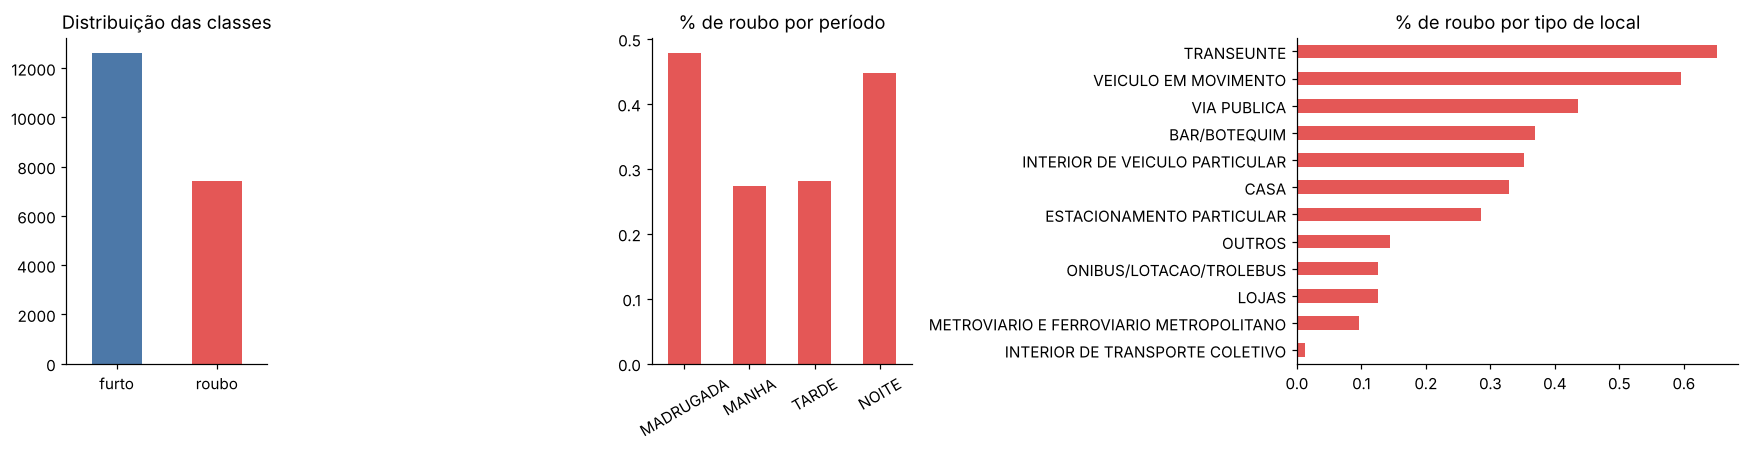

In [10]:
N = 20_000
amostra = base.sample(n=min(N, len(base)), random_state=SEED).reset_index(drop=True)
print("Amostra:", amostra.shape)
print(amostra["y"].map({0: "furto", 1: "roubo"}).value_counts(normalize=True).round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1.3, 2.2]})
amostra["y"].map({0: "furto", 1: "roubo"}).value_counts().plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"])
ax[0].set_title("Distribuição das classes"); ax[0].tick_params(axis="x", rotation=0); ax[0].set_xlabel("")
pd.crosstab(amostra["PERIODO"], amostra["y"], normalize="index")[1].reindex(
    ["MADRUGADA", "MANHA", "TARDE", "NOITE"]).plot.bar(ax=ax[1], color="#E45756")
ax[1].set_title("% de roubo por período"); ax[1].tick_params(axis="x", rotation=30); ax[1].set_xlabel("")
pd.crosstab(amostra["TIPO_LOCAL"], amostra["y"], normalize="index")[1].sort_values().plot.barh(ax=ax[2], color="#E45756")
ax[2].set_title("% de roubo por tipo de local"); ax[2].set_ylabel("")
plt.tight_layout(); plt.savefig(f"{FIGS}/eda.png", bbox_inches="tight"); plt.show()

## 7. Divisão treino / validação / teste (70 / 15 / 15, estratificada)
A divisão é feita **antes** de qualquer ajuste de codificação: o `OneHotEncoder` aprende as categorias só com o treino.
O **teste** fica guardado e só é usado uma vez, no final, para o modelo escolhido.

In [11]:
CAT = ["PERIODO", "DIA_SEMANA", "TIPO_LOCAL", "REGIAO", "BAIRRO", "MARCA"]
X = amostra.drop(columns="y"); y = amostra["y"].values
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f"Treino {len(X_tr)} | Validação {len(X_va)} | Teste {len(X_te)}")

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_tr[CAT])

def transforma(Xd):
    return ohe.transform(Xd[CAT]).astype("float32")

Xtr, Xva, Xte = transforma(X_tr), transforma(X_va), transforma(X_te)
N_ENTRADAS = Xtr.shape[1]
print("Número de entradas da MLP:", N_ENTRADAS, "(colunas one-hot)")
print({c: len(k) for c, k in zip(CAT, ohe.categories_)})

Treino 14000 | Validação 3000 | Teste 3000
Número de entradas da MLP: 79 (colunas one-hot)
{'PERIODO': 4, 'DIA_SEMANA': 7, 'TIPO_LOCAL': 12, 'REGIAO': 9, 'BAIRRO': 41, 'MARCA': 6}


**Escalonamento.** Todos os atributos são categóricos e viram colunas one-hot com valores 0/1, ou seja, já
estão na mesma escala. Por isso um `StandardScaler` não é necessário (e tiraria a interpretação 0/1).

**Desbalanceamento.** Como há mais furtos que roubos, usamos `class_weight` (pesos inversamente proporcionais
à frequência, calculados no treino) para a rede não "aprender" a responder só a classe majoritária.

In [12]:
pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr)
CLASS_WEIGHT = {0: pesos[0], 1: pesos[1]}
print("Pesos das classes:", {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

Pesos das classes: {0: np.float64(0.794), 1: np.float64(1.351)}


## 8. Implementação da MLP

Estrutura comum a todos os modelos:
* **Entrada**: um neurônio por atributo codificado.
* **Camadas ocultas densas** com **ReLU** — não-linearidade simples, não satura para valores positivos e treina rápido.
* **Saída**: 1 neurônio **sigmoide** → probabilidade de *roubo* (furto = 1 − p).
* **Perda**: `binary_crossentropy` (adequada a saída sigmoide em classificação binária).
* **Otimizador**: **Adam** (taxa de aprendizado adaptativa por parâmetro; bom padrão para dados tabulares).
* **EarlyStopping** monitorando `val_loss` (paciência 8) e restaurando os melhores pesos — evita treinar além do ponto ótimo.

In [13]:
def cria_mlp(ocultas, ativacao="relu", dropout=0.0, l2=0.0, lr=1e-3, nome="mlp"):
    reg = regularizers.l2(l2) if l2 else None
    m = keras.Sequential(name=nome)
    m.add(keras.Input(shape=(N_ENTRADAS,)))
    for n in ocultas:
        m.add(layers.Dense(n, activation=ativacao, kernel_regularizer=reg))
        if dropout: m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
              metrics=["accuracy"])
    return m

def metricas(y_true, p, limiar=0.5):
    y_pred = (p >= limiar).astype(int)
    return {"acuracia": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)}

## 9. Experimentos com arquiteturas

| Modelo | Camadas ocultas | Ativação | Regularização | LR | Ideia |
|---|---|---|---|---|---|
| **M1 – Base rasa** | 16 | ReLU | — | 1e-3 | Ponto de partida mínimo: 1 camada oculta pequena |
| **M2 – Média + Dropout** | 64 → 32 | ReLU | Dropout 0,3 | 1e-3 | Mais capacidade para combinar atributos, com dropout contra overfitting |
| **M3 – Profunda regularizada** | 128 → 64 → 32 | ReLU | Dropout 0,3 + L2 1e-4 | 5e-4 | Ainda mais capacidade; LR menor para descida mais estável |
| **M4 – Larga sem regularização** | 256 → 128 → 64 | ReLU | — | 1e-3 | Experimento de controle: mostra o efeito de tirar a regularização (overfitting) |
| **M5 – Média tanh** | 64 → 32 | tanh | Dropout 0,3 | 1e-3 | Mesma estrutura da M2 trocando a ativação |

Todos: batch size 64, até 60 épocas, `EarlyStopping(patience=8)` — exceto **M4**, treinada as 60 épocas
completas sem early stopping, de propósito, para observar o overfitting.

In [14]:
CONFIGS = [
    dict(nome="M1_base_16",            ocultas=[16],           dropout=0.0, l2=0.0,  lr=1e-3, early=True),
    dict(nome="M2_64_32_dropout",      ocultas=[64, 32],       dropout=0.3, l2=0.0,  lr=1e-3, early=True),
    dict(nome="M3_128_64_32_reg",      ocultas=[128, 64, 32],  dropout=0.3, l2=1e-4, lr=5e-4, early=True),
    dict(nome="M4_256_128_64_sem_reg", ocultas=[256, 128, 64], dropout=0.0, l2=0.0,  lr=1e-3, early=False),
    dict(nome="M5_64_32_tanh",         ocultas=[64, 32],       dropout=0.3, l2=0.0,  lr=1e-3, early=True, ativacao="tanh"),
]
EPOCAS, BATCH = 60, 64
resultados, historicos, modelos = [], {}, {}
for cfg in CONFIGS:
    tf.keras.utils.set_random_seed(SEED)
    m = cria_mlp(cfg["ocultas"], cfg.get("ativacao", "relu"), cfg["dropout"], cfg["l2"], cfg["lr"], cfg["nome"])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)] if cfg["early"] else []
    h = m.fit(Xtr, y_tr, validation_data=(Xva, y_va), epochs=EPOCAS, batch_size=BATCH,
              class_weight=CLASS_WEIGHT, callbacks=cbs, verbose=0)
    p_tr = m.predict(Xtr, verbose=0).ravel(); p_va = m.predict(Xva, verbose=0).ravel()
    mt, mv = metricas(y_tr, p_tr), metricas(y_va, p_va)
    resultados.append({"modelo": cfg["nome"], "params": m.count_params(), "epocas": len(h.history["loss"]),
                       "f1_treino": mt["f1"], **{f"{k}_val": v for k, v in mv.items()},
                       "loss_val_min": min(h.history["val_loss"])})
    historicos[cfg["nome"]], modelos[cfg["nome"]] = h.history, m
    print(f"{cfg['nome']:24s} épocas={len(h.history['loss']):2d}  F1 treino={mt['f1']:.3f}  F1 val={mv['f1']:.3f}  acc val={mv['acuracia']:.3f}")

M1_base_16               épocas=28  F1 treino=0.637  F1 val=0.637  acc val=0.705


M2_64_32_dropout         épocas=16  F1 treino=0.641  F1 val=0.633  acc val=0.697


M3_128_64_32_reg         épocas=23  F1 treino=0.649  F1 val=0.636  acc val=0.706


M4_256_128_64_sem_reg    épocas=60  F1 treino=0.752  F1 val=0.563  acc val=0.660


M5_64_32_tanh            épocas=18  F1 treino=0.623  F1 val=0.628  acc val=0.687


## 10. Comparação das arquiteturas (conjunto de **validação**)

In [15]:
tab = pd.DataFrame(resultados).set_index("modelo")
tab["gap_f1"] = tab["f1_treino"] - tab["f1_val"]
cols = ["params", "epocas", "acuracia_val", "precision_val", "recall_val", "f1_val", "f1_treino", "gap_f1", "loss_val_min"]
display(tab[cols].round(4))
tab[cols].round(4).to_csv(f"{MODELO}/comparacao_validacao.csv")

,params,epocas,acuracia_val,precision_val,recall_val,f1_val,f1_treino,gap_f1,loss_val_min
modelo,,,,,,,,,
M1_base_16,1297,28,0.7053,0.5852,0.6991,0.6371,0.6368,-0.0003,0.5680
M2_64_32_dropout,7233,16,0.6970,0.5736,0.7054,0.6327,0.6413,0.0085,0.5687
M3_128_64_32_reg,20609,23,0.7057,0.5861,0.6964,0.6365,0.6492,0.0127,0.5872
M4_256_128_64_sem_reg,61697,60,0.6597,0.5363,0.5919,0.5627,0.7520,0.1893,0.5596
M5_64_32_tanh,7233,18,0.6867,0.5599,0.7153,0.6282,0.6232,-0.0049,0.5749


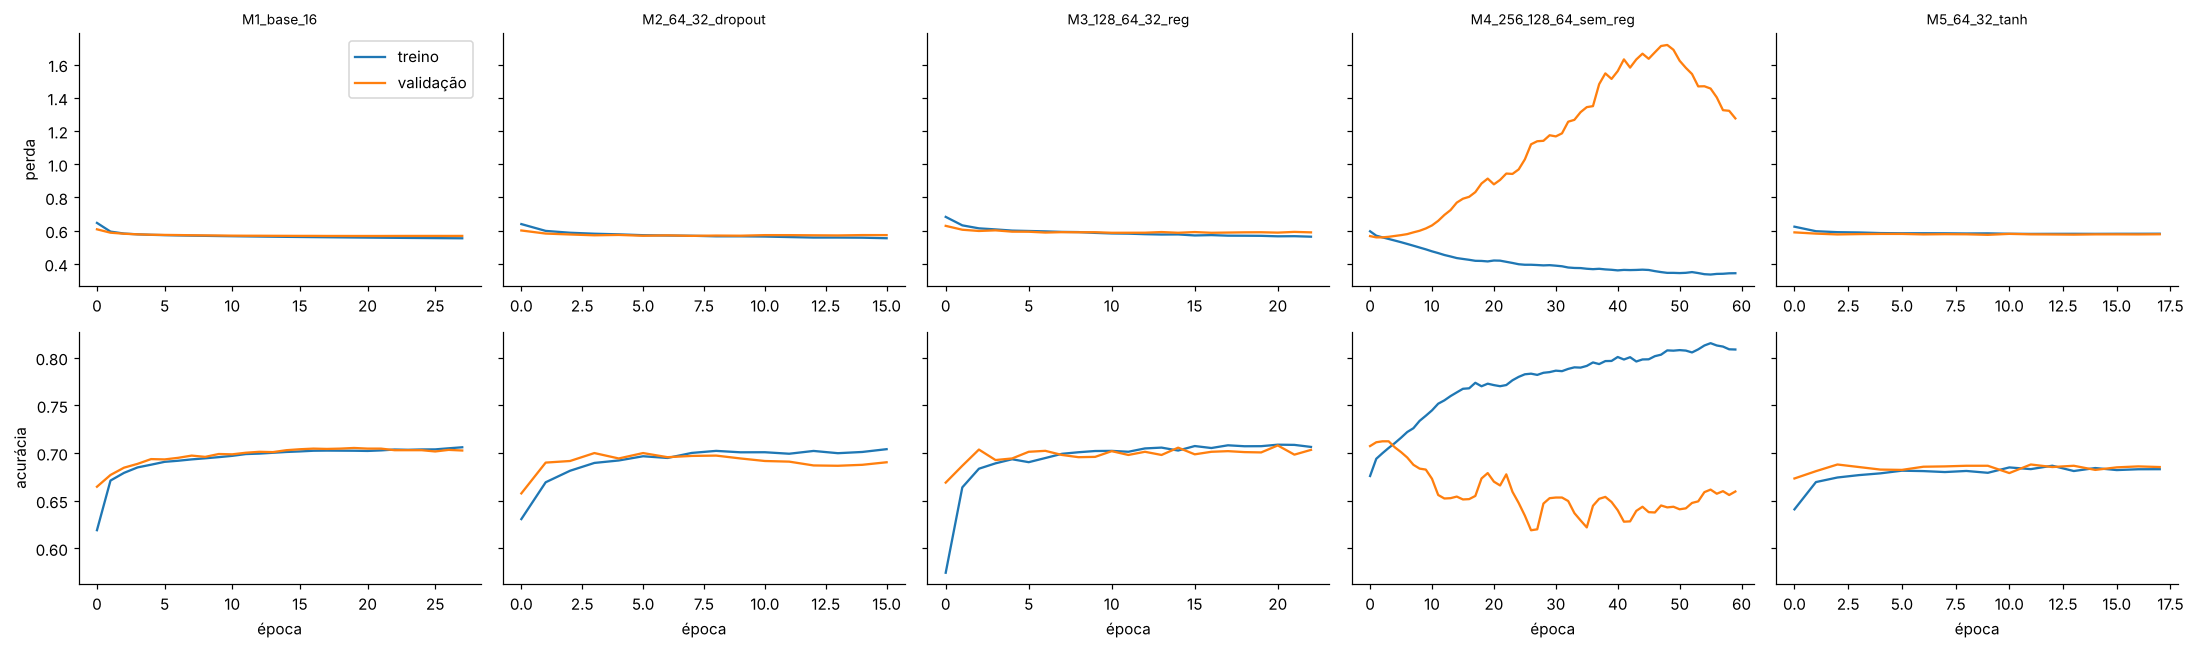

In [16]:
fig, axes = plt.subplots(2, len(CONFIGS), figsize=(4 * len(CONFIGS), 6), sharey="row")
for i, (nome, h) in enumerate(historicos.items()):
    axes[0, i].plot(h["loss"], label="treino"); axes[0, i].plot(h["val_loss"], label="validação")
    axes[0, i].set_title(nome, fontsize=9)
    axes[1, i].plot(h["accuracy"], label="treino"); axes[1, i].plot(h["val_accuracy"], label="validação")
axes[0, 0].set_ylabel("perda"); axes[1, 0].set_ylabel("acurácia"); axes[0, 0].legend()
for a in axes[1]: a.set_xlabel("época")
plt.tight_layout(); plt.savefig(f"{FIGS}/curvas_todos.png", bbox_inches="tight"); plt.show()

### Critério de escolha
Escolhemos o modelo com **maior F1 na validação** (equilibra precision e recall da classe *roubo*, mais
informativo que acurácia com classes desbalanceadas). Em caso de empate técnico (diferença < 0,005),
preferimos o de **menor gap treino–validação** (generaliza melhor) e menos parâmetros.

In [17]:
melhor_f1 = tab["f1_val"].max()
candidatos = tab[tab["f1_val"] >= melhor_f1 - 0.005].sort_values(["gap_f1", "params"])
ESCOLHIDO = candidatos.index[0]
print("Modelo escolhido:", ESCOLHIDO)
display(candidatos[["f1_val", "gap_f1", "params"]].round(4))
best = modelos[ESCOLHIDO]
best.summary()

Modelo escolhido: M1_base_16


,f1_val,gap_f1,params
modelo,,,
M1_base_16,0.6371,-0.0003,1297
M2_64_32_dropout,0.6327,0.0085,7233
M3_128_64_32_reg,0.6365,0.0127,20609


Model: "M1_base_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,893 (15.21 KB)

 Trainable params: 1,297 (5.07 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,596 (10.14 KB)

## 11. Modelo escolhido — curvas de treinamento e diagnóstico de overfitting/underfitting

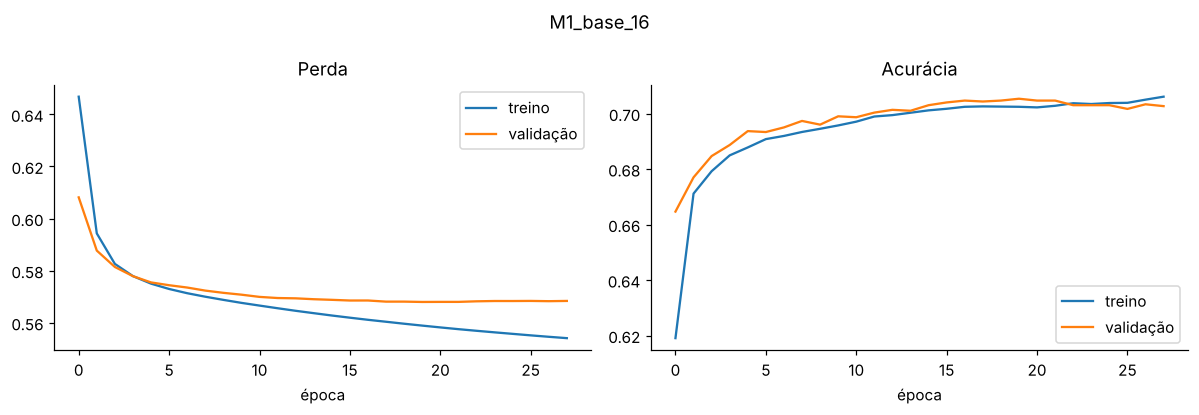

M4 (sem regularização): val_loss mínima na época 2 (0.5596) e final 1.2759; perda de treino caiu de 0.5698 para 0.3438 → overfitting.


In [18]:
h = historicos[ESCOLHIDO]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h["loss"], label="treino"); ax[0].plot(h["val_loss"], label="validação"); ax[0].set_title("Perda")
ax[1].plot(h["accuracy"], label="treino"); ax[1].plot(h["val_accuracy"], label="validação"); ax[1].set_title("Acurácia")
for a in ax: a.set_xlabel("época"); a.legend()
plt.suptitle(ESCOLHIDO); plt.tight_layout(); plt.savefig(f"{FIGS}/curvas_escolhido.png", bbox_inches="tight"); plt.show()

hm = historicos["M4_256_128_64_sem_reg"]
ep_min = int(np.argmin(hm["val_loss"]))
print(f"M4 (sem regularização): val_loss mínima na época {ep_min + 1} ({min(hm['val_loss']):.4f}) "
      f"e final {hm['val_loss'][-1]:.4f}; perda de treino caiu de {hm['loss'][ep_min]:.4f} para {hm['loss'][-1]:.4f} → overfitting.")

## 12. Avaliação final no conjunto de **teste** (usado uma única vez)

{'acuracia': 0.6737, 'precision': 0.5496, 'recall': 0.6541, 'f1': 0.5973}
              precision    recall  f1-score   support

       furto      0.771     0.685     0.726      1890
       roubo      0.550     0.654     0.597      1110

    accuracy                          0.674      3000
   macro avg      0.660     0.670     0.661      3000
weighted avg      0.689     0.674     0.678      3000



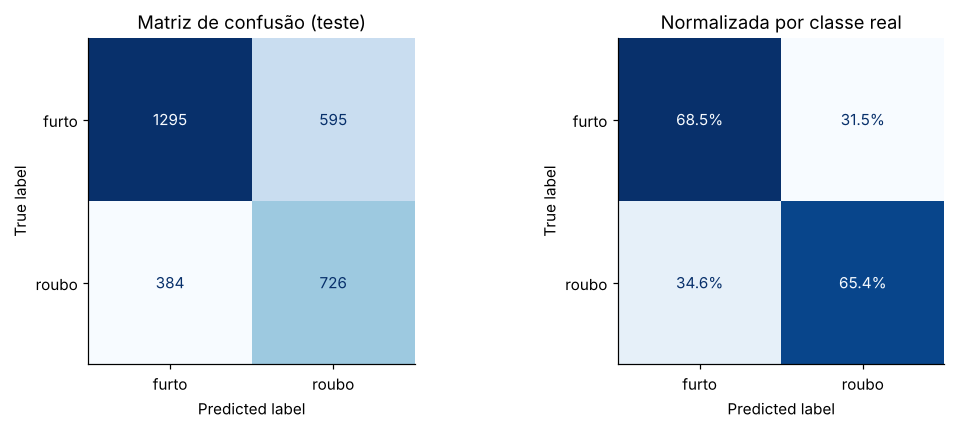

Referência 'sempre furto': acurácia=0.630, F1 roubo=0.000


In [19]:
p_te = best.predict(Xte, verbose=0).ravel()
mte = metricas(y_te, p_te)
print({k: round(v, 4) for k, v in mte.items()})
print(classification_report(y_te, (p_te >= 0.5).astype(int), target_names=["furto", "roubo"], digits=3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
cm = confusion_matrix(y_te, (p_te >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["furto", "roubo"]).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title("Matriz de confusão (teste)")
ConfusionMatrixDisplay(confusion_matrix(y_te, (p_te >= 0.5).astype(int), normalize="true"),
                       display_labels=["furto", "roubo"]).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".1%")
ax[1].set_title("Normalizada por classe real")
plt.tight_layout(); plt.savefig(f"{FIGS}/matriz_confusao.png", bbox_inches="tight"); plt.show()

# referência: um classificador que sempre chuta a classe majoritária
maj = int(np.mean(y_tr) >= 0.5)
print(f"Referência 'sempre {['furto','roubo'][maj]}': acurácia={accuracy_score(y_te, np.full_like(y_te, maj)):.3f}, F1 roubo={f1_score(y_te, np.full_like(y_te, maj), zero_division=0):.3f}")

## 13. Exportação do modelo para a aplicação web

In [20]:
best.save(f"{MODELO}/mlp_escolhida.keras")
densas = [l for l in best.layers if isinstance(l, layers.Dense)]
web = {
    "modelo": ESCOLHIDO,
    "entrada": {"hora_ciclica": False, "categoricas": CAT,
                "categorias": {c: [str(v) for v in cats] for c, cats in zip(CAT, ohe.categories_)}},
    "camadas": [{"W": l.get_weights()[0].round(6).tolist(), "b": l.get_weights()[1].round(6).tolist(),
                 "ativacao": l.get_config()["activation"]} for l in densas],
    "metricas_teste": {k: round(float(v), 4) for k, v in mte.items()},
    "n_amostra": int(len(amostra)), "periodo_dados": "2025",
}
with open(f"{APP}/model.json", "w", encoding="utf-8") as f:
    json.dump(web, f, ensure_ascii=False)

# exemplos para conferir que o app (JavaScript) reproduz a saída do Keras
ex = X_te.head(5).copy(); ex["p_roubo_keras"] = best.predict(transforma(ex), verbose=0).ravel()
ex.to_json(f"{MODELO}/exemplos_verificacao.json", orient="records", force_ascii=False)
json.dump({"escolhido": ESCOLHIDO, "teste": mte, "validacao": tab.round(4).reset_index().to_dict("records"),
           "n_capital_itens": int(len(sp)), "n_boletins": int(len(bo)), "n_validos": int(len(base)),
           "n_amostra": int(len(amostra)), "prop_roubo": float(amostra["y"].mean()),
           "split": [len(X_tr), len(X_va), len(X_te)], "n_entradas": int(N_ENTRADAS),
           "cm": cm.tolist(), "class_weight": {str(k): float(v) for k, v in CLASS_WEIGHT.items()}},
          open(f"{MODELO}/resumo.json", "w"), indent=2, default=float)
print("Salvo:", f"{APP}/model.json", f"({os.path.getsize(f'{APP}/model.json') / 1024:.0f} KB)")

Salvo: /home/claude/projeto/docs/model.json (29 KB)


## 14. Conclusões
* O desempenho de cada arquitetura, o modelo escolhido e as métricas de teste estão nas células acima.
* **Achado importante:** a presença da hora exata está muito ligada à classe por causa do formato do registro;
  tirar a hora exata e usar o período evitou que a rede aprendesse esse atalho.
* **Limitações:** os atributos disponíveis descrevem só o *contexto* (quando, onde, que aparelho) — não a dinâmica do
  fato —, então há sobreposição natural entre roubo e furto e um teto de desempenho; subnotificação e erros de
  preenchimento dos BOs; recorte de um único ano e de um único tipo de objeto (celular).
* **Interpretação correta:** a saída é P(roubo | ocorrência com essas características), e **não** o risco de um
  crime acontecer naquele lugar/horário.